# 07 · Modelo de Riesgo de Obras CFE
Clasificación binaria: predecir si una obra está en riesgo de no terminar en tiempo y forma.  
Usa **scikit-learn + MLflow + Unity Catalog Model Registry**.

In [0]:
%pip install databricks-feature-engineering --quiet

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import os, mlflow

# --- Cargar config.py (mismo patrón que _setup) ---
_nb_path = dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get()
_nb_dir = os.path.dirname(_nb_path)
exec(open(f"/Workspace{_nb_dir}/config.py").read())

# --- Catálogo y esquema ---
_user = spark.sql("SELECT current_user()").first()[0]
spark.sql(f"USE CATALOG `{CATALOG}`")
spark.sql(f"USE SCHEMA `{WORK_SCHEMA}`")
def tbl(name): return f"`{CATALOG}`.`{WORK_SCHEMA}`.`{name}`"

SCHEMA = WORK_SCHEMA  # alias para este notebook

# --- MLflow (parametrizado por usuario) ---
EXPERIMENT_NAME = f"/Users/{_user}/cfe_risk_model"
MODEL_NAME = f"{CATALOG}.{SCHEMA}.modelo_riesgo_obras"

mlflow.set_registry_uri("databricks-uc")
mlflow.set_experiment(EXPERIMENT_NAME)

print(f"📋 Config: CATALOG={CATALOG}, SCHEMA={SCHEMA}")
print(f"👤 Usuario: {_user}")
print(f"🔬 Experiment: {EXPERIMENT_NAME}")
print(f"📦 Model: {MODEL_NAME}")

📋 Config: CATALOG=dipidev, SCHEMA=default
👤 Usuario: juan.gordon@databricks.com
🔬 Experiment: /Users/juan.gordon@databricks.com/cfe_risk_model
📦 Model: dipidev.default.modelo_riesgo_obras


In [0]:
from pyspark.sql import functions as F, Window

# --- Leer de capa GOLD (pipeline medallion lab 03) ---
fact = spark.table(f"{CATALOG}.{SCHEMA}.gold_fact_obras")
dim_proy = spark.table(f"{CATALOG}.{SCHEMA}.gold_dim_proyectos")
dim_tipo = spark.table(f"{CATALOG}.{SCHEMA}.gold_dim_tipos_obra")
dim_res  = spark.table(f"{CATALOG}.{SCHEMA}.gold_dim_residencias")

# --- Star-schema joins ---
df = (
    fact
    .join(dim_proy.select("IdProyecto", "Cliente", "Contratista"),
          on="IdProyecto", how="left")
    .join(dim_tipo, on="IdTipoObra", how="left")
    .join(dim_res.select(F.col("IdResidenciaRegional"),
                         F.col("Nombre").alias("Residencia")),
          on="IdResidenciaRegional", how="left")
)

# --- Feature engineering (fechas ya son DATE nativo — sin parsing) ---
w_proj = Window.partitionBy("IdProyecto")

df_feat = df.select(
    F.col("IdObra"),
    F.col("NombreObra"),
    F.col("IdProyecto"),
    # Ratios financieros
    F.when((F.col("ImporteContratoMxn").isNotNull()) & (F.col("ImporteContratoMxn") > 0),
           F.col("ICM") / F.col("ImporteContratoMxn")).otherwise(0).alias("ratio_icm_contrato"),
    F.when((F.col("ImporteContratoMxn").isNotNull()) & (F.col("ImporteContratoMxn") > 0),
           F.col("CPTT") / F.col("ImporteContratoMxn")).otherwise(0).alias("ratio_cptt_contrato"),
    F.log1p(F.coalesce(F.col("ImporteContratoMxn"), F.lit(0))).alias("log_importe"),
    # Avance
    F.coalesce(F.col("AvanceActualConstruccion"), F.lit(0)).alias("avance_construccion"),
    F.coalesce(F.col("AvanceGeneralAP"), F.lit(0)).alias("avance_ap"),
    (F.coalesce(F.col("AvanceActualConstruccion"), F.lit(0)) -
     F.coalesce(F.col("AvanceGeneralAP"), F.lit(0))).alias("gap_avance"),
    # Tiempo (fechas ya son DATE — sin to_date())
    F.datediff(
        F.current_date(),
        F.coalesce(F.col("FechaInicioReal"), F.col("FechaInicioProgramada"))
    ).alias("dias_transcurridos"),
    F.datediff(
        F.col("FechaTerminacionProgramada"),
        F.col("FechaInicioProgramada")
    ).alias("dias_programados"),
    # Categóricos
    F.col("TipoObra").alias("tipo_obra"),
    F.col("kV").alias("voltaje_kv"),
    F.col("Residencia").alias("residencia"),
    # Features nuevos de Gold
    F.coalesce(F.col("Kilometros"), F.lit(0.0)).alias("kilometros"),
    F.when(F.lower(F.col("SituacionActual")).contains("suspendida"), 1
    ).otherwise(0).alias("esta_suspendida"),
    # Obras por proyecto
    F.count("IdObra").over(w_proj).alias("num_obras_proyecto"),
)

# ratio_tiempo = dias_transcurridos / dias_programados
df_feat = df_feat.withColumn(
    "ratio_tiempo",
    F.when((F.col("dias_programados").isNotNull()) & (F.col("dias_programados") > 0),
           F.col("dias_transcurridos") / F.col("dias_programados")).otherwise(F.lit(None))
)

# --- Target: en_riesgo ---
df_feat = df_feat.withColumn(
    "en_riesgo",
    F.when(
        ((F.col("avance_construccion") < 30) & (F.coalesce(F.col("ratio_tiempo"), F.lit(0)) > 0.5)) |
        ((F.col("avance_construccion") < 50) & (F.coalesce(F.col("ratio_tiempo"), F.lit(0)) > 0.8)) |
        (F.col("esta_suspendida") == 1) |
        (F.col("ratio_icm_contrato") > 1.2),
        1
    ).otherwise(0)
)

# Fill nulls y guardar
df_train = df_feat.na.fill(0, subset=["ratio_icm_contrato", "ratio_cptt_contrato",
                                       "dias_transcurridos", "dias_programados", "ratio_tiempo"])

df_train.write.format("delta").mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable(f"{CATALOG}.{SCHEMA}.training_riesgo_obras")

print(f"✅ Training table (from Gold): {df_train.count()} rows, {len(df_train.columns)} columns")
print(f"   Source: gold_fact_obras + gold_dim_proyectos + gold_dim_tipos_obra + gold_dim_residencias")
display(df_train.limit(5))

✅ Training table (from Gold): 318 rows, 19 columns
   Source: gold_fact_obras + gold_dim_proyectos + gold_dim_tipos_obra + gold_dim_residencias


IdObra,NombreObra,IdProyecto,ratio_icm_contrato,ratio_cptt_contrato,log_importe,avance_construccion,avance_ap,gap_avance,dias_transcurridos,dias_programados,tipo_obra,voltaje_kv,residencia,kilometros,esta_suspendida,num_obras_proyecto,ratio_tiempo,en_riesgo
35,S.E. NIZUC ELEVACION DE BUSES,3,13.99622038793108,0.0,15.0085157209922,0.0,100.0,-100.0,1463,1284,Subestación Eléctrica,115,RESIDENCIA REGIONAL PENINSULAR,0.0,0,1,1.1394080996884735,1
11,L.T. CAUCEL POTENCIA– PONIENTE,4,0.0,0.0,16.723980922420814,97.06,100.0,-2.9399999999999977,1012,104,Línea de Transmisión,115,RESIDENCIA REGIONAL PENINSULAR,5.4,0,8,9.73076923076923,0
10,S.E. PONIENTE,4,0.0,0.0,14.189977605528714,80.29,100.0,-19.709999999999994,1012,235,Subestación Eléctrica,115,RESIDENCIA REGIONAL PENINSULAR,0.0,0,8,4.306382978723405,0
3,S.E. MERIDA II,4,0.0,0.0,18.716132267872673,81.32,100.0,-18.680000000000007,986,209,Subestación Eléctrica,115,RESIDENCIA REGIONAL PENINSULAR,0.0,0,8,4.717703349282297,0
5,S.E. KANASÍN POTENCIA,4,0.0,0.0,17.885068398842915,86.94,100.0,-13.060000000000002,995,218,Subestación Eléctrica,115,RESIDENCIA REGIONAL PENINSULAR,0.0,0,8,4.564220183486238,0


In [0]:
from databricks.feature_engineering import FeatureEngineeringClient, FeatureLookup

fe = FeatureEngineeringClient()

FEATURE_TABLE = f"{CATALOG}.{SCHEMA}.features_riesgo_obras"
LABELS_TABLE = f"{CATALOG}.{SCHEMA}.training_riesgo_obras"

# ---- 1. Cargar los datos ya procesados ----
df_all = spark.table(LABELS_TABLE)

# Separar features (reutilizables) de labels (específicos del modelo)
feature_cols = ["IdObra",
                "ratio_icm_contrato", "ratio_cptt_contrato", "log_importe",
                "avance_construccion", "avance_ap", "gap_avance",
                "dias_transcurridos", "dias_programados", "ratio_tiempo",
                "tipo_obra", "voltaje_kv", "residencia",
                "kilometros", "esta_suspendida", "num_obras_proyecto"]

features_df = df_all.select(*feature_cols)

# ---- 2. Crear Feature Table con primary key ----
# FeatureEngineeringClient registra la tabla en Unity Catalog con metadata de Feature Store
try:
    fe.create_table(
        name=FEATURE_TABLE,
        primary_keys=["IdObra"],
        df=features_df,
        schema=features_df.schema,
        description="Features de riesgo para obras de construcción CFE. "
                    "Incluye ratios financieros, avance, tiempo y características categóricas.",
    )
    print(f"✅ Feature Table creada: {FEATURE_TABLE}")
except Exception as e:
    if "already exists" in str(e):
        # Si ya existe, actualizar con write_table
        fe.write_table(name=FEATURE_TABLE, df=features_df, mode="overwrite")
        print(f"♻️ Feature Table actualizada: {FEATURE_TABLE}")
    else:
        raise e

# ---- 3. Training set con FeatureLookup ----
# En vez de hacer joins manuales, Feature Store resuelve los features automáticamente
labels_df = df_all.select("IdObra", "en_riesgo")

feature_lookups = [
    FeatureLookup(
        table_name=FEATURE_TABLE,
        lookup_key="IdObra",  # clave para hacer join automático
    )
]

training_set = fe.create_training_set(
    df=labels_df,
    feature_lookups=feature_lookups,
    label="en_riesgo",
)

# Materializar el training set como pandas DataFrame
training_pdf = training_set.load_df().toPandas()
print(f"\n📊 Training set: {training_pdf.shape[0]} filas × {training_pdf.shape[1]} columnas")
print(f"   Features desde Feature Store: {len(feature_cols) - 1}")  # -1 por IdObra
print(f"   Primary key: IdObra")
print(f"\n🔑 Ventaja: cualquier modelo futuro puede reutilizar '{FEATURE_TABLE}'")
print(f"   sin recalcular features — solo necesita IdObra + label.")
display(training_pdf.head(5))

✅ Feature Table creada: dipidev.default.features_riesgo_obras

📊 Training set: 318 filas × 16 columnas
   Features desde Feature Store: 15
   Primary key: IdObra

🔑 Ventaja: cualquier modelo futuro puede reutilizar 'dipidev.default.features_riesgo_obras'
   sin recalcular features — solo necesita IdObra + label.


IdObra,ratio_icm_contrato,ratio_cptt_contrato,log_importe,avance_construccion,avance_ap,gap_avance,dias_transcurridos,dias_programados,ratio_tiempo,tipo_obra,voltaje_kv,residencia,tiene_problematica,num_obras_proyecto,en_riesgo
35,13.99622038793108,0.0,15.0085157209922,0.0,100.0,-100.0,1462,1284,1.1386292834890965,Subestación Eléctrica,115,RESIDENCIA REGIONAL PENINSULAR,0,1,1
11,0.0,0.0,16.723980922420814,97.06,100.0,-2.9399999999999977,1011,104,9.721153846153847,Línea de Transmisión,115,RESIDENCIA REGIONAL PENINSULAR,0,8,0
10,0.0,0.0,14.189977605528714,80.29,100.0,-19.709999999999994,1011,235,4.302127659574468,Subestación Eléctrica,115,RESIDENCIA REGIONAL PENINSULAR,0,8,0
3,0.0,0.0,18.716132267872673,81.32,100.0,-18.680000000000007,985,209,4.712918660287081,Subestación Eléctrica,115,RESIDENCIA REGIONAL PENINSULAR,0,8,0
5,0.0,0.0,17.885068398842915,86.94,100.0,-13.060000000000002,994,218,4.559633027522936,Subestación Eléctrica,115,RESIDENCIA REGIONAL PENINSULAR,0,8,0


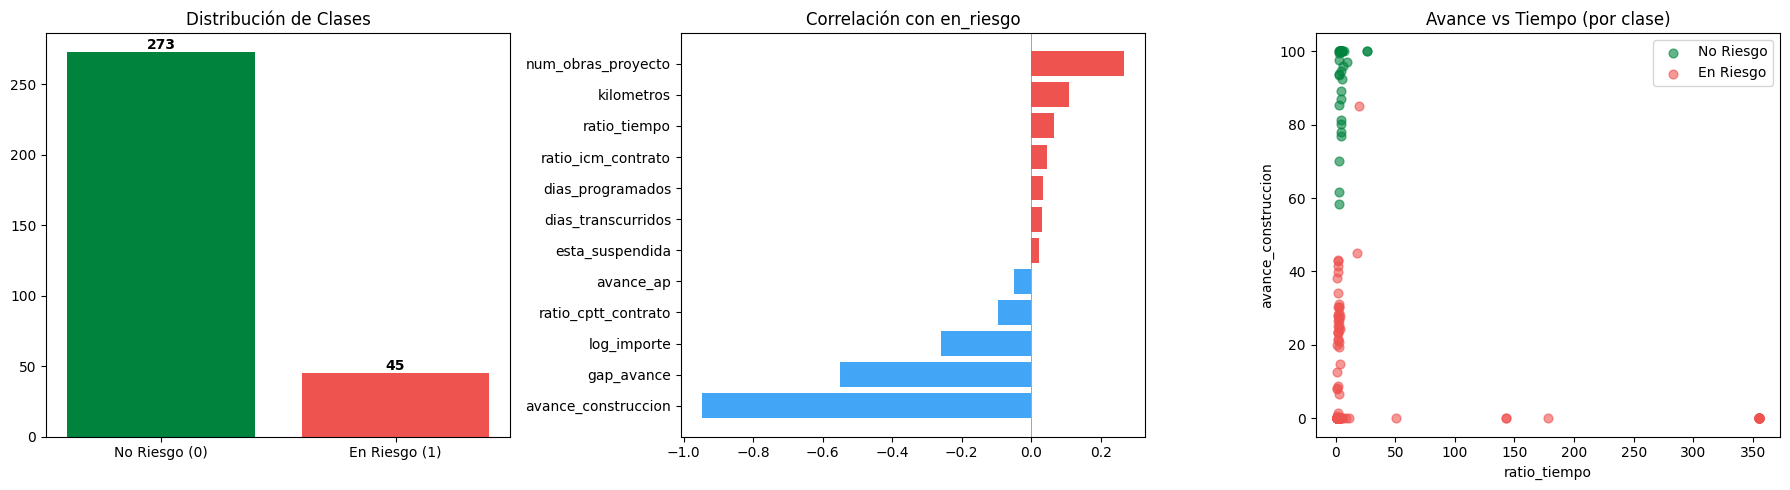


Dataset: 318 obras
En riesgo: 273 (85.8%)

Descriptive stats:


ratio_icm_contrato,ratio_cptt_contrato,log_importe,avance_construccion,avance_ap,gap_avance,dias_transcurridos,dias_programados,ratio_tiempo,kilometros,esta_suspendida,num_obras_proyecto
318.0,318.0,318.0,318.0,318.0,318.0,318.0,318.0,318.0,318.0,318.0,318.0
0.19,0.02,10.35,16.51,32.34,-15.83,5380.69,4834.86,15.33,9.81,0.0,7.64
0.86,0.12,8.86,33.28,45.1,53.29,55023.72,55025.19,63.16,33.16,0.06,5.12
0.0,0.0,0.0,0.0,0.0,-100.0,537.0,2.0,1.0,0.0,0.0,1.0
0.0,0.0,0.0,0.0,0.0,-65.33,872.0,359.0,1.71,0.0,0.0,3.0
0.0,0.0,15.96,0.0,0.0,0.0,946.0,450.0,2.01,0.0,0.0,7.0
0.0,0.0,18.31,8.27,98.0,0.0,1148.0,539.0,2.9,0.9,0.0,11.0
14.0,1.33,22.38,100.0,100.0,100.0,731457.0,730844.0,355.0,253.0,1.0,18.0


In [0]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

pdf = spark.table(f"{CATALOG}.{SCHEMA}.training_riesgo_obras").toPandas()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Class distribution
counts = pdf["en_riesgo"].value_counts()
axes[0].bar(["No Riesgo (0)", "En Riesgo (1)"], counts.values, color=["#00843D", "#EF5350"])
axes[0].set_title("Distribuci\u00f3n de Clases")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 2, str(v), ha="center", fontweight="bold")

# 2. Feature correlations with target
numeric_cols = ["ratio_icm_contrato", "ratio_cptt_contrato", "log_importe",
                "avance_construccion", "avance_ap", "gap_avance",
                "dias_transcurridos", "dias_programados", "ratio_tiempo",
                "kilometros", "esta_suspendida", "num_obras_proyecto"]
corrs = pdf[numeric_cols + ["en_riesgo"]].corr()["en_riesgo"].drop("en_riesgo").sort_values()
colors = ["#EF5350" if v > 0 else "#42A5F5" for v in corrs.values]
axes[1].barh(corrs.index, corrs.values, color=colors)
axes[1].set_title("Correlaci\u00f3n con en_riesgo")
axes[1].axvline(0, color="gray", linewidth=0.5)

# 3. Avance vs ratio_tiempo colored by target
for label, color, name in [(0, "#00843D", "No Riesgo"), (1, "#EF5350", "En Riesgo")]:
    subset = pdf[pdf["en_riesgo"] == label]
    axes[2].scatter(subset["ratio_tiempo"], subset["avance_construccion"],
                    c=color, alpha=0.6, label=name, s=40)
axes[2].set_xlabel("ratio_tiempo")
axes[2].set_ylabel("avance_construccion")
axes[2].set_title("Avance vs Tiempo (por clase)")
axes[2].legend()

plt.tight_layout()
plt.show()

# Summary stats
print(f"\nDataset: {len(pdf)} obras")
print(f"En riesgo: {pdf['en_riesgo'].sum()} ({pdf['en_riesgo'].mean()*100:.1f}%)")
print(f"\nDescriptive stats:")
display(pdf[numeric_cols].describe().round(2))

In [0]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from mlflow.models import infer_signature
import numpy as np

# Load data
pdf = spark.table(f"{CATALOG}.{SCHEMA}.training_riesgo_obras").toPandas()

# Define features
numeric_features = ["ratio_icm_contrato", "ratio_cptt_contrato", "log_importe",
                    "avance_construccion", "avance_ap", "gap_avance",
                    "dias_transcurridos", "dias_programados", "ratio_tiempo",
                    "kilometros", "esta_suspendida", "num_obras_proyecto"]
categorical_features = ["tipo_obra", "voltaje_kv", "residencia"]
all_features = numeric_features + categorical_features

X = pdf[all_features]
y = pdf["en_riesgo"]

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Preprocessing + model pipeline
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])

model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200, max_depth=8, class_weight="balanced",
        random_state=42, n_jobs=-1))
])

# Train with MLflow tracking
mlflow.sklearn.autolog(log_input_examples=True, silent=True)

with mlflow.start_run(run_name="rf_riesgo_obras") as run:
    model_pipeline.fit(X_train, y_train)
    
    # Evaluate
    y_pred = model_pipeline.predict(X_test)
    f1 = f1_score(y_test, y_pred)
    
    # Log extra metrics
    mlflow.log_metric("test_f1", f1)
    mlflow.log_metric("test_accuracy", (y_pred == y_test).mean())
    
    # Log model with signature
    signature = infer_signature(X_train.head(100), model_pipeline.predict(X_train.head(100)))
    mlflow.sklearn.log_model(
        model_pipeline, "model",
        signature=signature,
        input_example=X_train.head(3)
    )
    
    best_run_id = run.info.run_id

print(f"Run ID: {best_run_id}")
print(f"\nTest F1 Score: {f1:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Riesgo", "En Riesgo"]))
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")

/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/18 00:24:27 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://adb-7405607040498050.10.azuredatabricks.net/ml/experiments/827142329458586/models/m-ddb51d2e8aa446fcb

Run ID: 95291dcc26054c12bff486fa4ec781fd

Test F1 Score: 1.0000

Classification Report:
              precision    recall  f1-score   support

   No Riesgo       1.00      1.00      1.00         9
   En Riesgo       1.00      1.00      1.00        55

    accuracy                           1.00        64
   macro avg       1.00      1.00      1.00        64
weighted avg       1.00      1.00      1.00        64

Confusion Matrix:
[[ 9  0]
 [ 0 55]]


Features: 9 numéricas + 3 categóricas = 12
(Excluidas por leakage: ['avance_construccion', 'ratio_tiempo', 'gap_avance'])
Target: 273 en riesgo (85.8%) / 45 sin riesgo (14.2%)
  Logistic Regression                  F1=0.9173 ± 0.0332
  Random Forest                        F1=0.9801 ± 0.0103
  Gradient Boosting                    F1=0.9777 ± 0.0176
  HistGradientBoosting (≈LightGBM)     F1=0.9741 ± 0.0153
  SVM (RBF)                            F1=0.9283 ± 0.0327

COMPARACIÓN DE MODELOS (5-Fold CV, sin features con leakage)


Modelo,F1 (mean),F1 (std),Accuracy,Precision,Recall
Random Forest,0.9801,0.0103,0.9655,0.9755,0.9853
Gradient Boosting,0.9777,0.0176,0.9622,0.9822,0.9742
HistGradientBoosting (≈LightGBM),0.9741,0.0153,0.956,0.9787,0.9706
SVM (RBF),0.9283,0.0327,0.8866,1.0,0.8679
Logistic Regression,0.9173,0.0332,0.8678,0.9792,0.8642


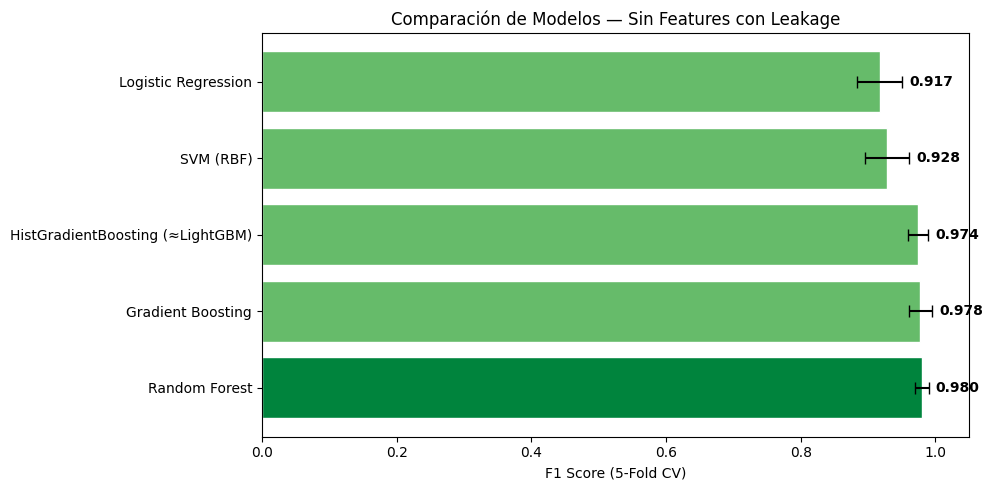


🏆 Mejor modelo: Random Forest con F1 = 0.9801 ± 0.0103


In [0]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import mlflow

# ---------- DATA (sin features con leakage) ----------
pdf = spark.table(f"{CATALOG}.{SCHEMA}.training_riesgo_obras").toPandas()

# Excluir features que DEFINEN el target
LEAKY = ["avance_construccion", "ratio_tiempo", "gap_avance"]

numeric_feat = ["ratio_icm_contrato", "ratio_cptt_contrato", "log_importe",
                "avance_ap", "dias_transcurridos", "dias_programados",
                "kilometros", "esta_suspendida", "num_obras_proyecto"]
categorical_feat = ["tipo_obra", "voltaje_kv", "residencia"]

X = pdf[numeric_feat + categorical_feat]
y = pdf["en_riesgo"]

print(f"Features: {len(numeric_feat)} numéricas + {len(categorical_feat)} categóricas = {X.shape[1]}")
print(f"(Excluidas por leakage: {LEAKY})")
print(f"Target: {y.sum()} en riesgo ({y.mean()*100:.1f}%) / {(~y.astype(bool)).sum()} sin riesgo ({(1-y.mean())*100:.1f}%)")

# ---------- PREPROCESSING ----------
preproc = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("scl", StandardScaler())]), numeric_feat),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="unknown")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), categorical_feat),
])

# ---------- MODELOS ----------
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, class_weight="balanced",
        random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42),
    "HistGradientBoosting (≈LightGBM)": HistGradientBoostingClassifier(
        max_iter=200, max_depth=6, learning_rate=0.1,
        class_weight="balanced", random_state=42),
    "SVM (RBF)": SVC(
        kernel="rbf", class_weight="balanced", probability=True, random_state=42),
}

# ---------- CROSS-VALIDATION (5-Fold) + MLflow ----------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, clf in models.items():
    pipe = Pipeline([("preproc", preproc), ("clf", clf)])
    
    scores = cross_validate(
        pipe, X, y, cv=cv,
        scoring=["f1", "accuracy", "precision", "recall"],
        return_train_score=False, n_jobs=-1
    )
    
    row = {
        "Modelo": name,
        "F1 (mean)": scores["test_f1"].mean(),
        "F1 (std)": scores["test_f1"].std(),
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
    }
    results.append(row)
    
    # Log to MLflow
    with mlflow.start_run(run_name=f"compare_{name.lower().replace(' ', '_')}"):
        mlflow.log_param("model_type", name)
        mlflow.log_param("leaky_features_removed", True)
        mlflow.log_param("n_features", X.shape[1])
        mlflow.log_metric("cv_f1_mean", row["F1 (mean)"])
        mlflow.log_metric("cv_f1_std", row["F1 (std)"])
        mlflow.log_metric("cv_accuracy", row["Accuracy"])
        mlflow.log_metric("cv_precision", row["Precision"])
        mlflow.log_metric("cv_recall", row["Recall"])
    
    print(f"  {name:35s}  F1={row['F1 (mean)']:.4f} ± {row['F1 (std)']:.4f}")

# ---------- COMPARISON TABLE ----------
df_results = pd.DataFrame(results).sort_values("F1 (mean)", ascending=False)
print("\n" + "="*80)
print("COMPARACIÓN DE MODELOS (5-Fold CV, sin features con leakage)")
print("="*80)
display(df_results.round(4))

# ---------- CHART ----------
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#00843D" if i == 0 else "#66BB6A" for i in range(len(df_results))]
ax.barh(df_results["Modelo"], df_results["F1 (mean)"], xerr=df_results["F1 (std)"],
        color=colors, capsize=4, edgecolor="white")
ax.set_xlabel("F1 Score (5-Fold CV)")
ax.set_title("Comparación de Modelos — Sin Features con Leakage")
ax.set_xlim(0, 1.05)
for i, (v, s) in enumerate(zip(df_results["F1 (mean)"], df_results["F1 (std)"])):
    ax.text(v + s + 0.01, i, f"{v:.3f}", va="center", fontweight="bold")
plt.tight_layout()
plt.show()

best = df_results.iloc[0]
print(f"\n🏆 Mejor modelo: {best['Modelo']} con F1 = {best['F1 (mean)']:.4f} ± {best['F1 (std)']:.4f}")

In [0]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

# Use best run from previous cell
run_id = best_run_id
print(f"Best run ID: {run_id}")

# Register model in Unity Catalog
model_uri = f"runs:/{run_id}/model"
result = mlflow.register_model(model_uri=model_uri, name=MODEL_NAME)
print(f"Registered model: {result.name} version {result.version}")

# Set alias and tags
client.set_registered_model_alias(MODEL_NAME, "champion", result.version)
client.update_registered_model(
    MODEL_NAME,
    description="Modelo de riesgo de obras de construcci\u00f3n CFE. "
                "Clasificaci\u00f3n binaria (en_riesgo) basada en avance, costos y tiempo."
)
client.set_model_version_tag(MODEL_NAME, result.version, "task", "binary_classification")
client.set_model_version_tag(MODEL_NAME, result.version, "primary_metric", "f1")
client.set_model_version_tag(MODEL_NAME, result.version, "dataset", f"{CATALOG}.{SCHEMA}.training_riesgo_obras")

print(f"Model '{MODEL_NAME}' v{result.version} registered with alias 'champion'")

Best run ID: 95291dcc26054c12bff486fa4ec781fd


Registered model 'dipidev.default.modelo_riesgo_obras' already exists. Creating a new version of this model...
2026/10/18 00:24:55 WARNING mlflow.tracking._model_registry.fluent: Run with id 95291dcc26054c12bff486fa4ec781fd has no artifacts at artifact path 'model', registering model based on models:/m-ddb51d2e8aa446fcbfde4db820259b56 instead


Uploading artifacts:   0%|          | 0/12 [00:00<?, ?it/s]

🔗 Created version '4' of model 'dipidev.default.modelo_riesgo_obras': https://adb-7405607040498050.10.azuredatabricks.net/explore/data/models/dipidev/default/modelo_riesgo_obras/version/4?o=7405607040498050


Registered model: dipidev.default.modelo_riesgo_obras version 4
Model 'dipidev.default.modelo_riesgo_obras' v4 registered with alias 'champion'


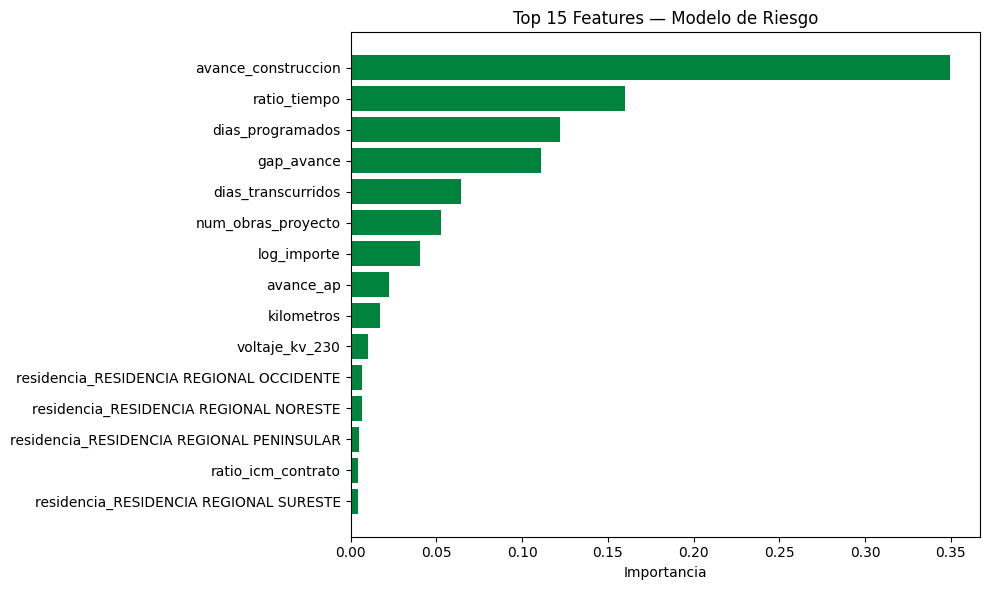

Total features after encoding: 37

Top 5: [('avance_construccion', np.float64(0.3495)), ('ratio_tiempo', np.float64(0.1602)), ('dias_programados', np.float64(0.1222)), ('gap_avance', np.float64(0.1109)), ('dias_transcurridos', np.float64(0.0642))]


In [0]:
import matplotlib.pyplot as plt
import numpy as np

# Load champion model
model = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@champion")

# Extract feature names from the ColumnTransformer (includes one-hot encoded names)
preproc = model.named_steps["preprocessor"]
feature_names = preproc.get_feature_names_out()

# Get importances from the classifier
clf = model.named_steps["classifier"]
importances = clf.feature_importances_

# Clean up feature names (remove transformer prefixes like "num__" / "cat__")
clean_names = [n.replace("num__", "").replace("cat__", "") for n in feature_names]

# Sort and plot top 15
idx = np.argsort(importances)[-15:][::-1]
top_names = [clean_names[i] for i in idx]
top_vals = importances[idx]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(top_names)), top_vals[::-1], color="#00843D")
ax.set_yticks(range(len(top_names)))
ax.set_yticklabels(top_names[::-1])
ax.set_xlabel("Importancia")
ax.set_title("Top 15 Features — Modelo de Riesgo")
plt.tight_layout()
plt.show()

print(f"Total features after encoding: {len(feature_names)}")
print(f"\nTop 5: {list(zip(top_names[:5], top_vals[:5].round(4)))}")

In [0]:
from datetime import datetime
import pandas as pd
import mlflow

mlflow.set_registry_uri("databricks-uc")

# Feature columns (mismos que en el entrenamiento)
numeric_features = ["ratio_icm_contrato", "ratio_cptt_contrato", "log_importe",
                    "avance_construccion", "avance_ap", "gap_avance",
                    "dias_transcurridos", "dias_programados", "ratio_tiempo",
                    "kilometros", "esta_suspendida", "num_obras_proyecto"]
categorical_features = ["tipo_obra", "voltaje_kv", "residencia"]

# CATALOG, SCHEMA y MODEL_NAME vienen de _setup + Config ML

# Load all obras as pandas
all_pdf = spark.table(f"{CATALOG}.{SCHEMA}.training_riesgo_obras").toPandas()

# Load champion model
champion = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@champion")

# Score with the pipeline (uses same feature columns as training)
X_score = all_pdf[numeric_features + categorical_features]
preds = champion.predict(X_score)

# Get probabilities
try:
    probs = champion.predict_proba(X_score)[:, 1]
except Exception:
    probs = preds.astype(float)

# Build predictions DataFrame
pred_pdf = pd.DataFrame({
    "IdObra": all_pdf["IdObra"],
    "NombreObra": all_pdf["NombreObra"],
    "risk_probability": probs,
    "risk_label": preds,
    "scored_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
})

# Save to Delta
pred_sdf = spark.createDataFrame(pred_pdf)
pred_sdf.write.format("delta").mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable(f"{CATALOG}.{SCHEMA}.predicciones_riesgo_obras")

print(f"Predictions saved: {len(pred_pdf)} rows")
print(f"\nRisk distribution:")
print(pred_pdf["risk_label"].value_counts())
print(f"\nTop 10 highest risk obras:")
display(pred_pdf.nlargest(10, "risk_probability")[["IdObra", "NombreObra", "risk_probability", "risk_label"]])

Predictions saved: 318 rows

Risk distribution:
risk_label
1    273
0     45
Name: count, dtype: int64

Top 10 highest risk obras:


IdObra,NombreObra,risk_probability,risk_label
14,L.T. TUXPAN VAPOR-A3580-POZA RICA,1.0,1
59,L.T. LAS MESAS – HUEJUTLA II,1.0,1
63,L.T. LAS MESAS ENTQ. AXTLA - TAMAZUNCHALE,1.0,1
52,S.E. HUASTECA AMPL,1.0,1
32,S.E. LAS MESAS BCO. 1,1.0,1
42,S.E. AXTLA AMPL.,1.0,1
45,S.E. HUEJUTLA II AMPL.,1.0,1
19,S.E. POTRERILLOS,1.0,1
24,S.E. QUERÉTARO POTENCIA,1.0,1
43,L.T. SABANCUY – CARMEN (TRAMO MARINO),1.0,1


## Resumen

Se construyó un modelo de clasificación binaria para predecir **obras en riesgo** de la CFE, usando:

- **318 obras** con 15 features (12 numéricas + 3 categóricas) derivadas de avance, costos, tiempo, kilómetros y situación actual
- **scikit-learn RandomForest** (200 trees, class_weight=balanced) con pipeline de preprocesamiento
- **MLflow** para tracking de experimentos y **Unity Catalog** para registro del modelo

### Artefactos generados
| Artefacto | Ubicación |
| --- | --- |
| Training data | `dipidev.default.training_riesgo_obras` (from Gold layer) |
| Modelo registrado | `dipidev.default.modelo_riesgo_obras` (alias: champion) |
| Predicciones | `dipidev.default.predicciones_riesgo_obras` |

### ⚠️ Nota sobre F1 = 1.0 (leakage del target)

El modelo alcanza F1 perfecto porque la definición del target (`en_riesgo`) depende directamente de features usados en el entrenamiento:

- `ratio_tiempo > 0.8` se cumple para **el 100%** de las obras (mínimo = 1.0)
- Por lo tanto, el target se reduce a `avance_construccion < 50` — que es el feature #1 (33% importancia)
- Esto es **data leakage**: el modelo aprende la regla exacta, no generaliza

**Para mejorar:**
1. Excluir `avance_construccion`, `ratio_tiempo` y `gap_avance` del entrenamiento (son parte de la definición del target)
2. Redefinir el target como predicción a futuro (ej. ¿terminará a tiempo dado su ritmo actual?)
3. Usar cross-validation temporal si se tienen snapshots históricos

### Próximos pasos
- Servir el modelo con **Model Serving** para scoring en tiempo real
- Conectar predicciones al **Dashboard Ejecutivo CFE** 
- Programar re-entrenamiento periódico con **Lakeflow Jobs**
- Agregar la tabla `notas_obra` (de la app) como feature adicional
- Ajustar la definición de `en_riesgo` para evitar leakage